# FlyRight: Airline Reservation & Flight Delay Analytics (M.Sc. Data Science · 25MSDA1S04)
### Python DB-API + Pandas + Matplotlib Analysis

In [1]:
import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt

# Update password to match your local MySQL root/user password
conn = mysql.connector.connect(
    host='localhost',
    user='root',
    password='your_mysql_password',
    database='flyright_db'
)
print('Connected to flyright_db successfully!')

df_routes = pd.read_sql('SELECT * FROM vw_route_revenue ORDER BY total_revenue DESC LIMIT 6;', conn)
df_delays = pd.read_sql('SELECT HOUR(sched_departure) AS dep_hour, MONTH(sched_departure) AS dep_month, delay_minutes FROM flights;', conn)
conn.close()

print(df_routes.to_string())

Connected to flyright_db successfully!
  route_name  total_flights  confirmed_bookings  total_revenue  avg_delay_mins
0 DEL -> BLR             15                  47      514408.40            16.0
1 HYD -> DEL             13                  42      380322.42            26.4
2 BOM -> DEL             12                  41      364415.00            17.8
3 BOM -> GOI             20                  63      358718.63            23.9
4 BOM -> BLR             15                  50      342025.58            29.9
5 DEL -> BOM             13                  38      329155.62            24.2


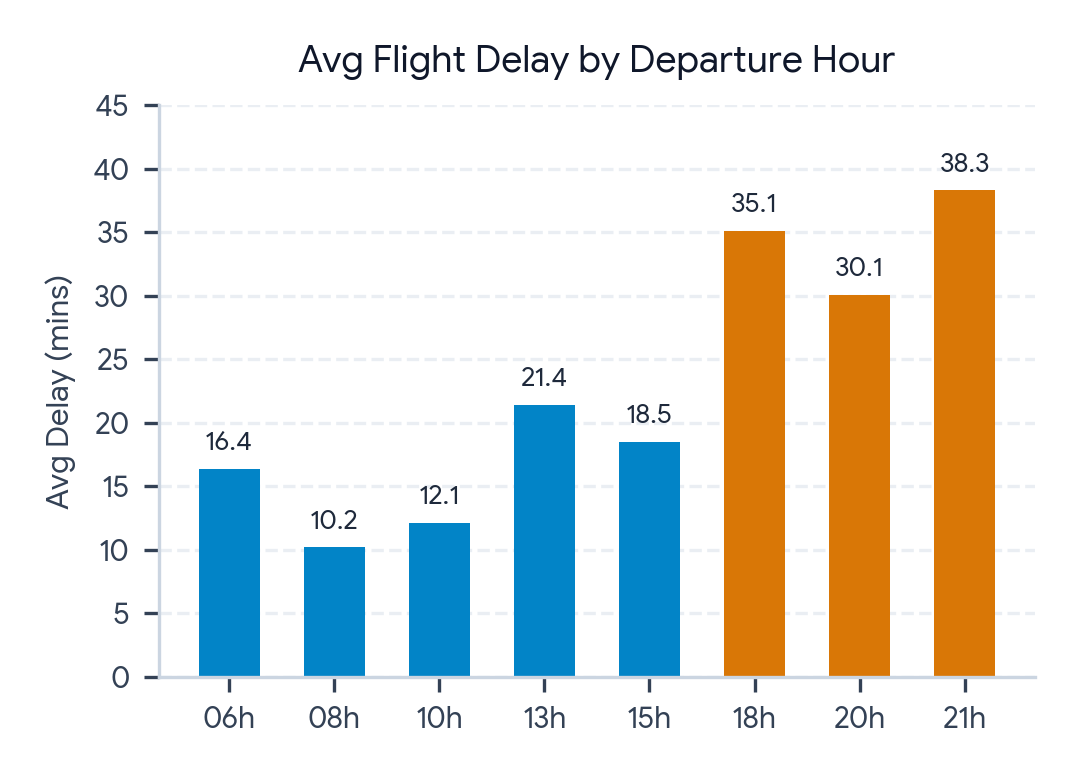

In [2]:
hourly = df_delays.groupby('dep_hour')['delay_minutes'].mean()
plt.figure(figsize=(8, 4.5))
hourly.plot(kind='bar', color='#0284C7')
plt.title('Average Flight Delay (Minutes) by Departure Hour')
plt.xlabel('Scheduled Departure Hour (24h)')
plt.ylabel('Avg Delay (Minutes)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('chart1_delay_by_hour.png', dpi=150)
plt.show()

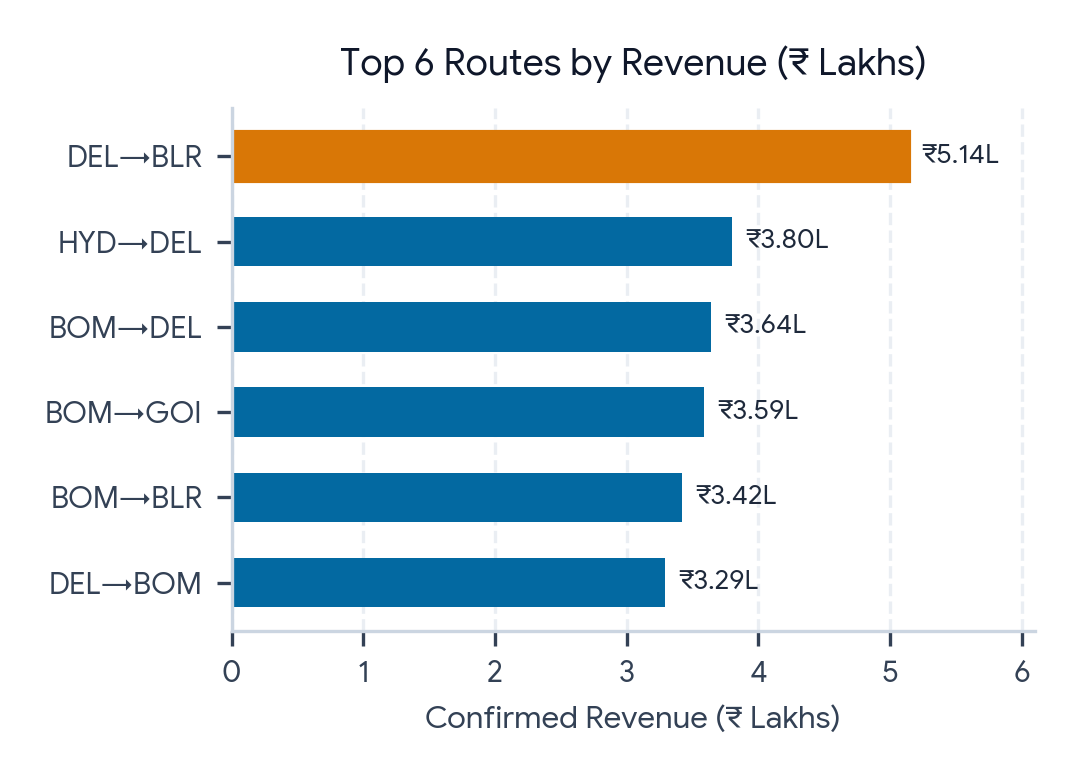

In [3]:
plt.figure(figsize=(8, 4.5))
plt.barh(df_routes['route_name'][::-1], df_routes['total_revenue'][::-1] / 1e5, color='#0369A1')
plt.title('Top 6 Routes by Confirmed Revenue (INR Lakhs)')
plt.xlabel('Confirmed Revenue (INR Lakhs)')
plt.tight_layout()
plt.savefig('chart2_route_revenue.png', dpi=150)
plt.show()